# 05 - What we found, and the limit of this dataset

A short recap of the patterns, and one honest statement about what RSV data can and
cannot answer.

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; R scripts expect to run from here
pd.set_option("display.width", 120)

def run_r(script):
    """Run one of the R figure scripts from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))


## Patterns observed

1. **RSV strongly suppresses CpG** genome-wide (O/E about 0.24), while the other three
   GC dinucleotides sit near 1. So CpG is specifically avoided.
2. **Composition varies a lot between genes.** The G gene is the most GC-rich and most
   distinctive region; it is the natural region to focus on.
3. **RSV-A has removed nearly all CpG from NS1 and NS2**, its two interferon-antagonist
   genes, at the same GC content as RSV-B. This is the clearest pattern we found.
4. **The apparent rise in CpG over time in RSV-B is lineage replacement, not evolution.**
   Within lineages it declines, matching the paper's direction.
5. Comparisons at the level of individual lineages were **too few to be conclusive** and
   did not survive multiple-testing correction.

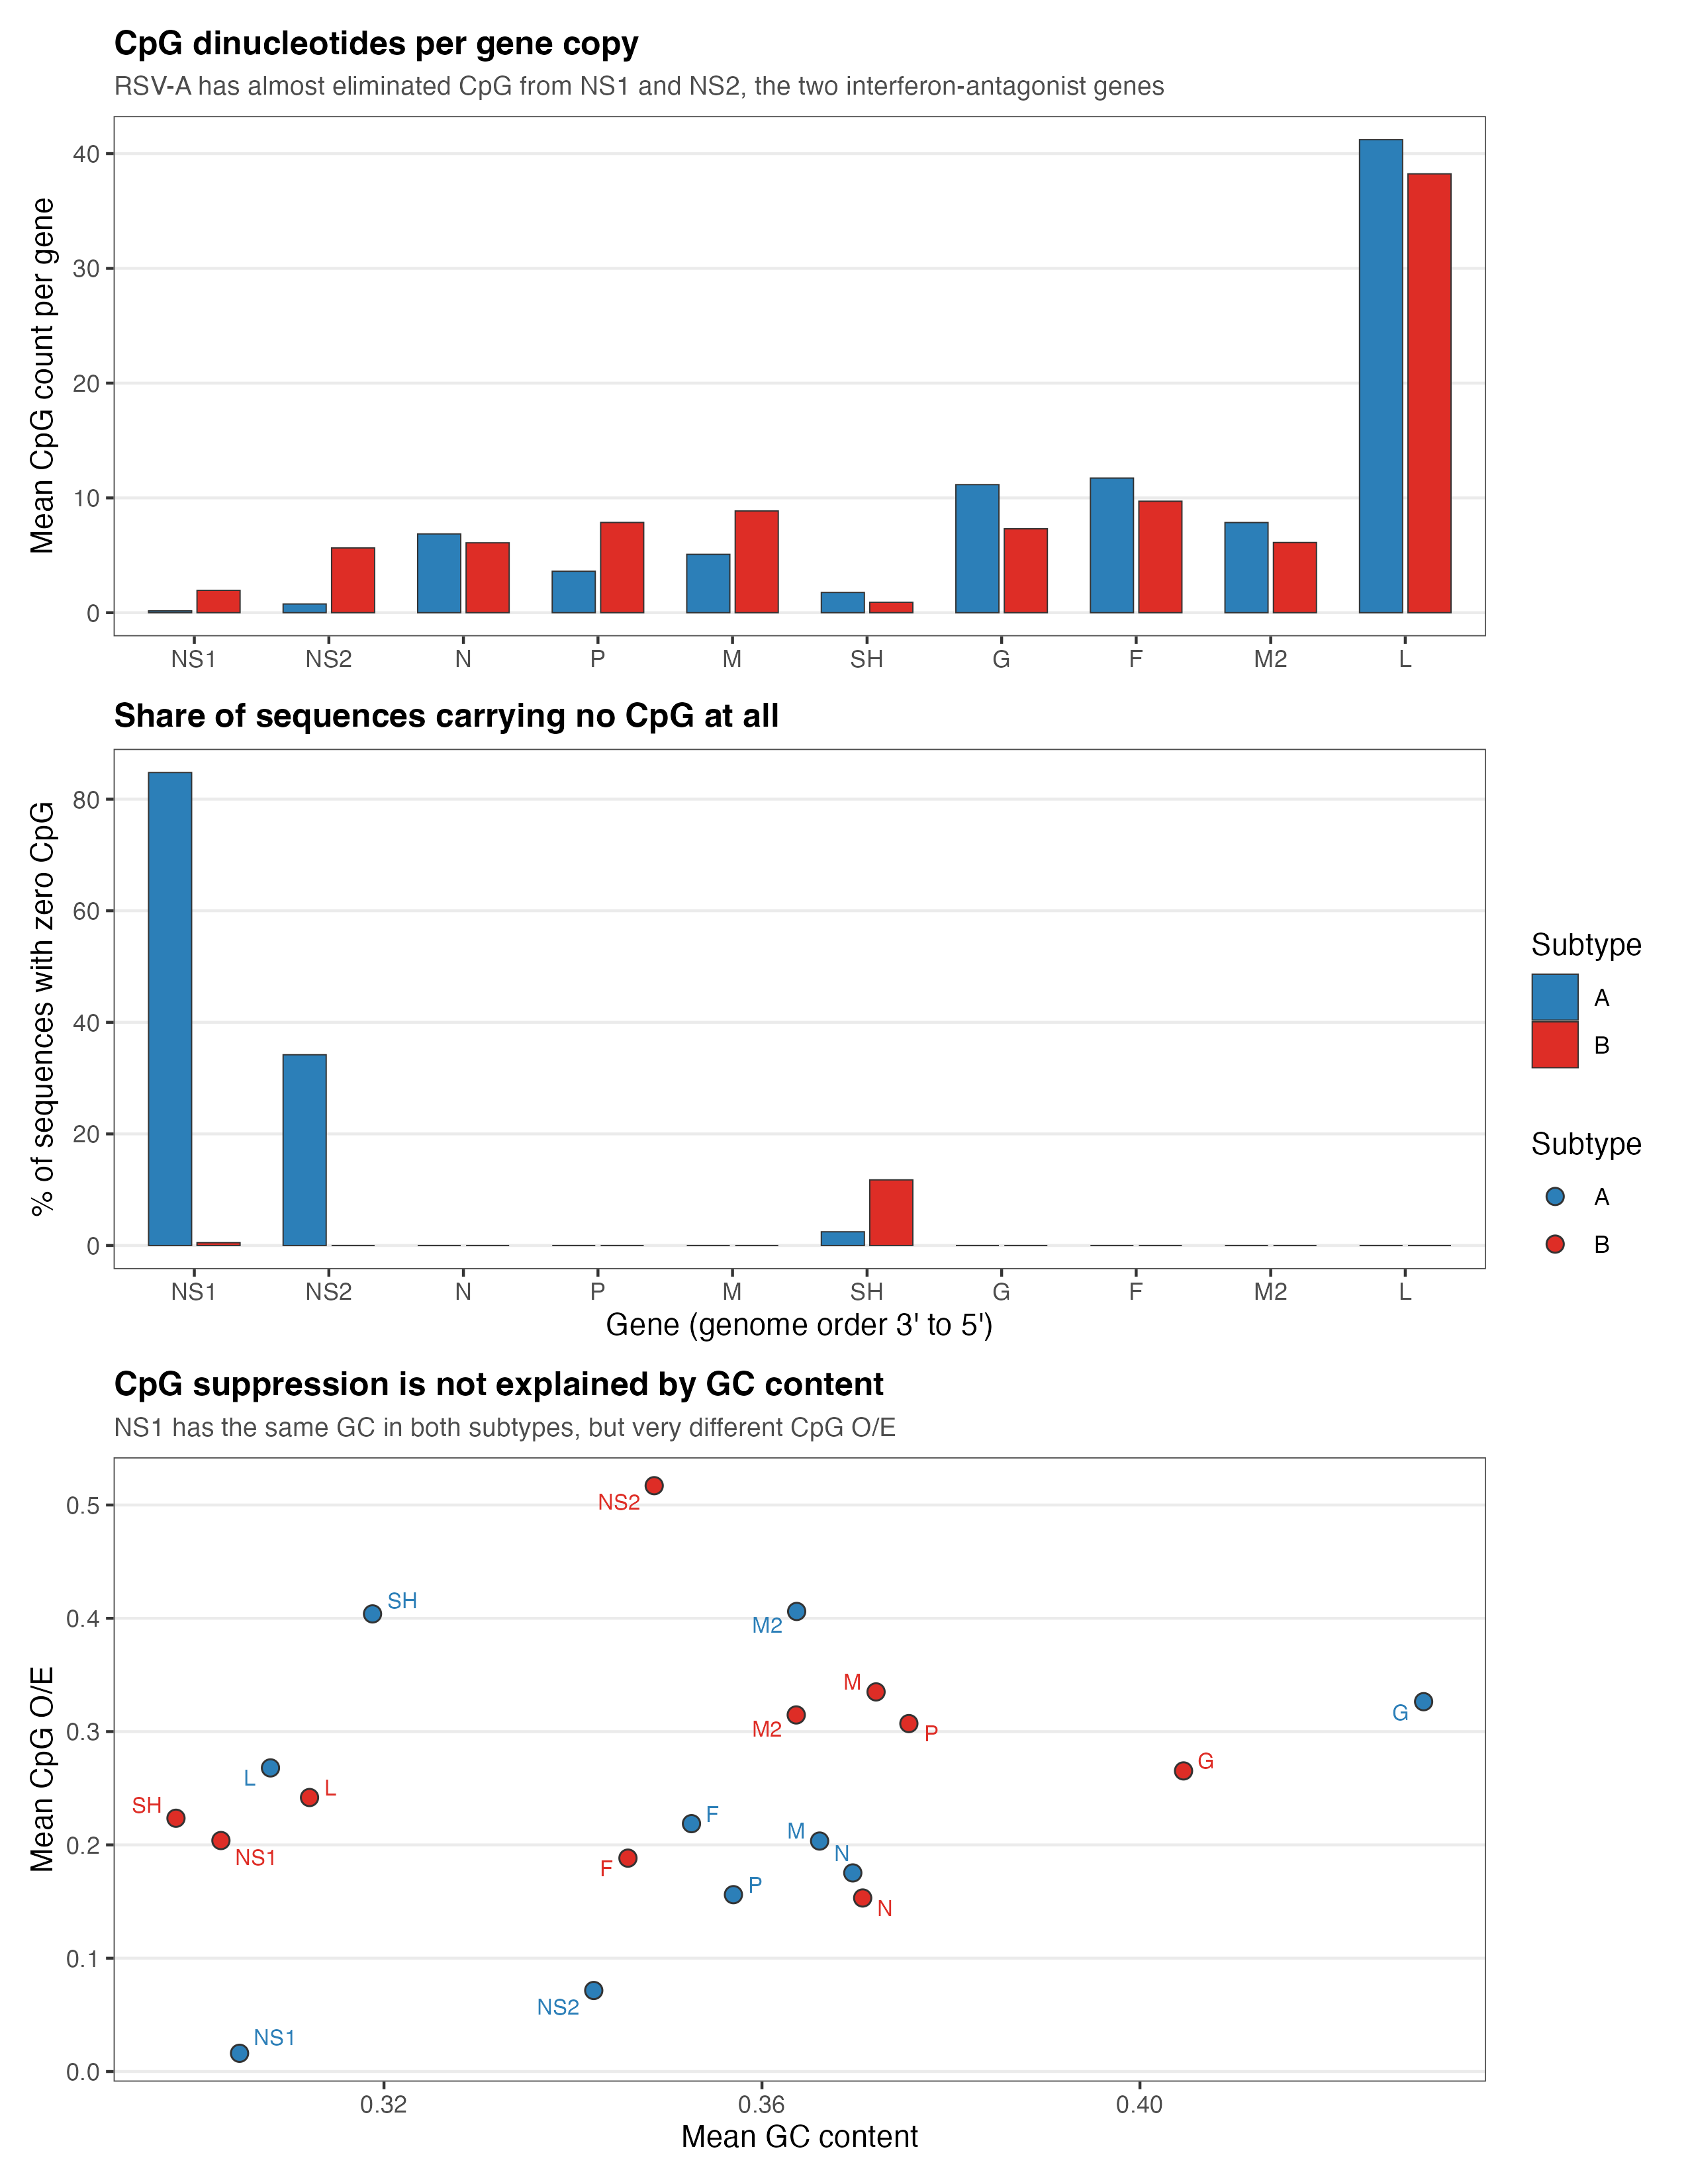

In [2]:
show("fig11_cpg_depletion.png")

## The limit of this dataset

The paper's central comparison is between viruses that achieved **sustained** transmission
in a host and those that only caused **sporadic** infections. Those labels come from
knowing each virus's history, not from its sequence.

**Every GISAID RSV sequence is from a human, and RSV has circulated in humans for
decades.** So this dataset contains only one of the two classes. No model can learn to
separate sustained from sporadic here, because there are no sporadic examples.

That does not make the work useless: the pipeline applies to any virus, and finding 3
stands on its own. But answering the original question needs a dataset with both classes,
such as a panel of paramyxoviruses where Nipah and Hendra supply the sporadic side.
See `docs/PROJECT_BRIEF.md`.